# Multichannel ROI and calibration pairs

This notebook confirms the `MultichannelROI` on a source image, then calls the pipeline to read the calibration file list, crop, localize, pair each moving channel to channel 0, and merge pairs across files.

In [ ]:
# `import smlm` 需要 Py_Smile 在 sys.path 上; notebook 放进子目录后自己找一下
import pathlib
import sys

for _q in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_q / 'smlm' / '__init__.py').is_file():
        sys.path.insert(0, str(_q))
        break


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from smlm.camera import EMCCD
from smlm.io import load_raw
from smlm.multiplex import MultichannelROI

In [3]:
CALIB_FILES = [r"G:\PacBio\近观DNA_FRET\20261123\std1.sif",
               r"G:\PacBio\近观DNA_FRET\20261123\std2.sif",
               r"G:\PacBio\近观DNA_FRET\20261123\std3.sif"]
if not Path(CALIB_FILES[0]).is_file():
    raise FileNotFoundError(f"SIF file not found: {CALIB_FILES[0]}")
raw = load_raw(CALIB_FILES[0])
camera = EMCCD(conv_factor=5.75, em_gain=300)
stack = camera.process(raw)
print(f"ImageStack: {stack.shape}, pixel_size={stack.pixel_size}")

ImageStack: (10, 512, 512), pixel_size=None


In [4]:
height, width = stack.shape[1:]
split_x = 256
ROI_Y = (0, height)
ROI_X = (0+10, split_x-10)
CHANNEL_OFFSETS = ((0, 0), (0, split_x))  # (dy, dx), relative to channel 0
CHANNELS = ("g", "r")

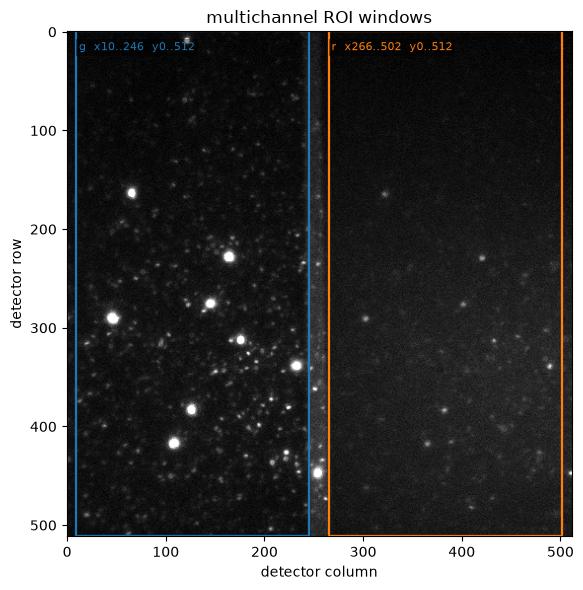

In [5]:
roi = MultichannelROI(
    y=ROI_Y,
    x=ROI_X,
    offsets=CHANNEL_OFFSETS,
    channels=CHANNELS,
)
show = roi.show_roi(stack)

## Validate the ROI and generate merged pairs

First confirm the crop on the initial file. The pipeline then uses its built-in calibration defaults and returns a channel-aligned list of merged `PairSet`s; the reference channel slot is `None`.

In [6]:
from smlm.multiplex import pair_multichannel_files

PAIR_REFERENCE = CHANNELS[0]
multiChannelPairs = pair_multichannel_files(
    CALIB_FILES, roi, reference=PAIR_REFERENCE)
#multiChannelPairs

--- [1/3] std1.sif
  localizations: g=48, r=11
  [r -> g] tol=6.0 px 只配到 8 对, 停止细化
  [r -> g] 0 pairs
--- [2/3] std2.sif
  localizations: g=92, r=29
  [r -> g] tol=  6.0 px ->    20 pairs, shift=(-0.44, -0.38) px
  [r -> g] 20 pairs
--- [3/3] std3.sif
  localizations: g=62, r=17
  [r -> g] tol=  6.0 px ->    14 pairs, shift=(-0.38, -0.36) px
  [r -> g] 14 pairs
--- merged r -> g: 34 pairs from 2 files


## Fit registration per moving channel

The reference is taken from the `None` slot produced by `pair_multichannel_files`, so fitting uses the same reference as pairing. Each calibration records the ROI windows and offsets, source files, and moving/reference channel names.

In [7]:
from smlm.multiplex import fit_multichannel_pairs

multiChannelCalibrations = fit_multichannel_pairs(multiChannelPairs, roi)
multiChannelCalibrations

--- fitting r -> g
  交叉验证选阶 (指标 cv_p84_px):
    order 1  ( 3 参数)  med 0.166  p84 0.295  rms 0.311  max 1.305 px
    order 2  ( 6 参数)  med 0.171  p84 0.293  rms 0.328  max 1.319 px
    order 3  (10 参数)  med 0.233  p84 0.479  rms 0.377  max 1.301 px
    -> 选 order 1
  iter 0: kept    34/   34   thr=0.53 px   median=0.150 px
  iter 1: kept    32/   34   thr=0.43 px   median=0.145 px
  多项式阶数 = 1  (3 参数)
  poly  : median 0.145 px   rms 0.152 px
  affine: median 0.145 px   rms 0.152 px


[None, DualViewCalibration(r->g, order=1, coarse=(0, 256))]

## Save multichannel calibration


In [9]:
from smlm.multiplex import MultiChannelCalibrationBundle

MULTICHANNEL_CALIBRATION_PATH = Path(CALIB_FILES[0]).with_name(
    f"{Path(CALIB_FILES[0]).stem}_multichannel_calibration.npz"
)
multiChannelCalibrationBundle = MultiChannelCalibrationBundle.from_fit(
    multiChannelCalibrations, roi, CALIB_FILES)
multiChannelCalibrationBundle.save(MULTICHANNEL_CALIBRATION_PATH)

WindowsPath('G:/PacBio/近观DNA_FRET/20261123/std1_multichannel_calibration.npz')

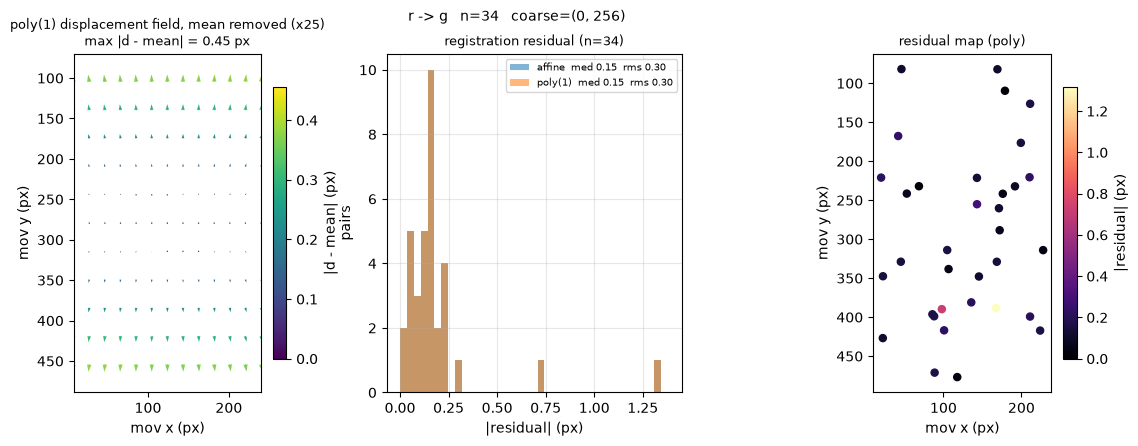

In [8]:
from smlm.multiplex import plot_overview

for channel_index, calibration in enumerate(multiChannelCalibrations):
    if calibration is not None:
        plot_overview(calibration, multiChannelPairs[channel_index])
plt.show()